# Étape 3 (axe 2D) : identification d'un modèle LSTM

Même méthode que pour l'axe vertical (`02_identification/lstm/lstm_identification.ipynb`), avec deux entrées et trois sorties :

- **entrées** : `U_common` (poussée commune) et `TH_CMD` ($\theta_{cmd}$, consigne d'inclinaison envoyée au stabilisateur d'attitude) ;
- **sorties** : $a_x$, $a_z$ et $\theta$.

Pourquoi ces sorties : l'environnement de l'étape 4 intègre $a_x$ et $a_z$ pour obtenir $v_x, x, v_z, z$ (comme $a_z \to z$ en 1D), et l'agent a besoin de l'inclinaison $\theta$ pour stabiliser le drone.

**Commande en cascade.** Le drone seul est instable : une petite différence avant/arrière gardée constante le fait basculer. Un modèle identifié de `U_diff` vers $\theta$ n'est donc valable que pour les commandes vues dans les données, et l'agent SAC exploitait ses erreurs (il gardait `U_diff` saturé, le LSTM prédisait un $\theta$ stable, alors que le vrai drone se retourne).

On fait donc comme sur les vrais drones : un stabilisateur d'attitude (PD, celui de `generate_data.m`) fait partie du système, et on commande la **consigne d'inclinaison** $\theta_{cmd}$ au lieu de `U_diff`. Ce système est stable, donc identifiable :
$$\Delta u = K_\theta(\theta_{cmd} - \theta) - K_q\,\dot\theta, \qquad K_\theta = 0{,}08,\; K_q = 0{,}04$$

Chargement des données

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler

D = loadmat("../../data/raw/landing_data.mat")
names = [str(n[0]) for n in D["names_Y"][0]]
iy = {n: i for i, n in enumerate(names)}
Ts = float(D["Ts"].squeeze())

U = np.stack([D["U_common"], D["TH_CMD"]], axis=-1)              # (500, 400, 2) : entrées
Y = D["Y"][:, :, [iy["ax"], iy["az"], iy["theta"]]]               # (500, 400, 3) : sorties
out_names = ["a_x [m/s²]", "a_z [m/s²]", "theta [rad]"]
print("U :", U.shape, "  Y :", Y.shape)

U : (500, 400, 2)   Y : (500, 400, 3)


Data processing

Même découpage que dans `04_landing_data.ipynb` (par expérience, 70 / 15 / 15).
Les scalers MinMax sont ajustés **sur le train uniquement**, une colonne par grandeur.
En 1D l'entrée était déjà dans $[-1, 1]$ ; ici les deux entrées n'ont pas la même échelle, donc on les met aussi à l'échelle.

In [15]:
split = np.load("../../data/raw/landing_split.npz")
index_training, index_validation, index_test = split["train"], split["val"], split["test"]

U_training, Y_training = U[index_training], Y[index_training]
U_validation, Y_validation = U[index_validation], Y[index_validation]
U_test, Y_test = U[index_test], Y[index_test]
print(len(index_training), len(index_validation), len(index_test))

# reshape(-1, 2) : on empile tous les instants de toutes les expériences, une colonne par grandeur
scaler_u = MinMaxScaler(feature_range=(-1, 1)).fit(U_training.reshape(-1, 2))
scaler_y = MinMaxScaler(feature_range=(-1, 1)).fit(Y_training.reshape(-1, 3))

def scale(scaler, A):
    return scaler.transform(A.reshape(-1, A.shape[-1])).reshape(A.shape)

U_training_mm, U_validation_mm, U_test_mm = [scale(scaler_u, A) for A in (U_training, U_validation, U_test)]
Y_training_mm, Y_validation_mm, Y_test_mm = [scale(scaler_y, A) for A in (Y_training, Y_validation, Y_test)]

350 75 75


In [16]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import TensorBoardLogger

Conversion to tensor (les séquences font déjà 400 pas = 20 s)

In [17]:
def to_tensors(U_mm, Y_mm):
    return torch.tensor(U_mm, dtype=torch.float32), torch.tensor(Y_mm, dtype=torch.float32)

X_train, Y_train = to_tensors(U_training_mm, Y_training_mm)
X_val,   Y_val   = to_tensors(U_validation_mm, Y_validation_mm)
X_test,  Y_test_t = to_tensors(U_test_mm, Y_test_mm)

train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=32, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, Y_val),     batch_size=32)
test_loader  = DataLoader(TensorDataset(X_test, Y_test_t), batch_size=32)

print(X_train.shape, Y_train.shape)   # (350, 400, 2) (350, 400, 3)

torch.Size([350, 400, 2]) torch.Size([350, 400, 3])


Model

Identique au modèle 1D, seules les tailles changent : `input_size=2`, sortie de taille 3, et `hidden_size=64` (le 2D a plus de dynamique à retenir : $\theta$ est l'intégrale double de `U_diff`).

In [18]:
class model_nn(L.LightningModule):
    def __init__(self, hidden_size=64, lr=3e-3):
        super().__init__()
        self.save_hyperparameters()
        self.rnn = nn.LSTM(input_size=2, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 3)
        self.loss_fn = nn.MSELoss()

    def forward(self, x):
        h, _ = self.rnn(x)
        return self.head(h)

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.loss_fn(self(x), y)
        self.log("train_loss", loss, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        self.log("val_loss", self.loss_fn(self(x), y), prog_bar=True)

    def test_step(self, batch, batch_idx):
        x, y = batch
        self.log("test_loss", self.loss_fn(self(x), y))

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

Training (moins d'expériences qu'en 1D, donc plus d'époques et une patience plus longue)

In [19]:
model = model_nn()
logger = TensorBoardLogger("../../results/tensorboard", name="lstm_2d")

checkpoint = ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1,
                             dirpath=logger.log_dir, filename="lstm2d-{epoch:03d}-{val_loss:.5f}")
early_stop = EarlyStopping(monitor="val_loss", mode="min", patience=50)

trainer = L.Trainer(max_epochs=600, logger=logger, callbacks=[checkpoint, early_stop])
trainer.fit(model, train_loader, val_loader)
trainer.test(model, test_loader, ckpt_path="best")
print("meilleur modèle :", checkpoint.best_model_path)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/results/tensorboard/lstm_2d/version_2 exists and is not empty.


┏━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ rnn     │ LSTM    │ 17.4 K │ train │     0 │
│ 1 │ head    │ Linear  │    195 │ train │     0 │
│ 2 │ loss_fn │ MSELoss │      0 │ train │     0 │
└───┴─────────┴─────────┴────────┴───────┴───────┘

Trainable params: 17.6 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 17.6 K                                                                                               
Total estimated model params size (MB): 0.070                                                                      
Modules in train mode: 3                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/Users/AlbanDERUE/Documents/CS/2A/Data Driven 
Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

/Users/AlbanDERUE/Documents/CS/2A/Data Driven 
Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.p
y:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of 
the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.

... (3 outputs left out)

Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_loss         │  0.00012693770986516029   │
└───────────────────────────┴───────────────────────────┘

/Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


meilleur modèle : /Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/results/tensorboard/lstm_2d/version_2/lstm2d-epoch=180-val_loss=0.00012.ckpt


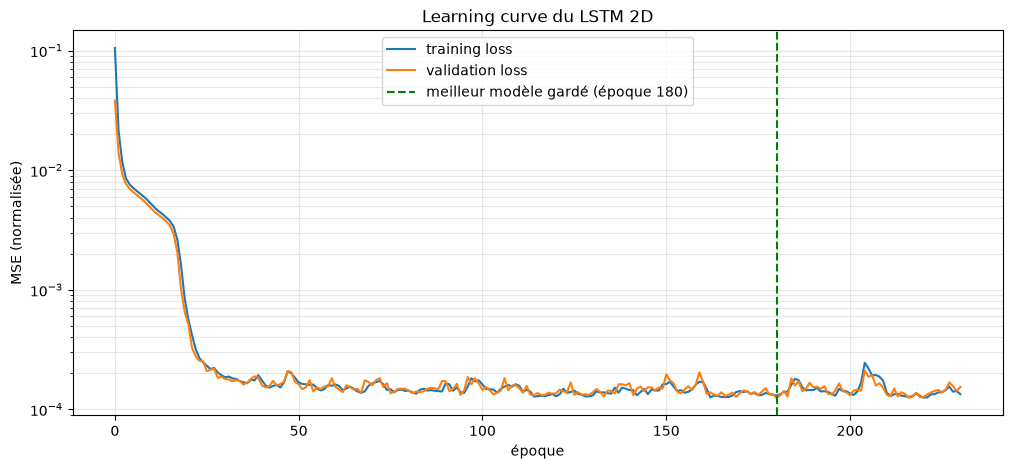

In [20]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

ea = EventAccumulator(logger.log_dir).Reload()
train = np.array([e.value for e in ea.Scalars("train_loss_epoch")])
val   = np.array([e.value for e in ea.Scalars("val_loss")])
epochs = np.arange(len(val))
best = val.argmin()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(epochs, train, label="training loss")
ax.plot(epochs, val, label="validation loss")
ax.axvline(best, color="g", ls="--", label=f"meilleur modèle gardé (époque {best})")
ax.set_yscale("log"); ax.set_xlabel("époque"); ax.set_ylabel("MSE (normalisée)")
ax.set_title("Learning curve du LSTM 2D"); ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.show()

Résultats sur le jeu de test : RMSE par sortie, comparée à l'écart-type du signal (si RMSE ≪ écart-type, le modèle explique bien le signal)

In [21]:
model = model_nn.load_from_checkpoint(checkpoint.best_model_path)
model.eval()

with torch.no_grad():
    pred_mm = model(X_test.to(model.device)).cpu().numpy()
pred_all = scaler_y.inverse_transform(pred_mm.reshape(-1, 3)).reshape(pred_mm.shape)   # unités physiques

rmse = np.sqrt(np.mean((pred_all - Y_test) ** 2, axis=(0, 1)))
std = Y_test.reshape(-1, 3).std(axis=0)
for n, r, s in zip(out_names, rmse, std):
    print(f"{n:12s} RMSE = {r:.3f}   écart-type du signal = {s:.3f}   ratio = {r / s:.2f}")

rmse_par_exp = np.sqrt(np.mean((pred_all - Y_test) ** 2, axis=1))   # (75, 3)
pire = rmse_par_exp[:, 2].argmax()                                   # pire expérience sur theta

a_x [m/s²]   RMSE = 0.047   écart-type du signal = 1.334   ratio = 0.03
a_z [m/s²]   RMSE = 0.010   écart-type du signal = 1.273   ratio = 0.01
theta [rad]  RMSE = 0.007   écart-type du signal = 0.136   ratio = 0.05


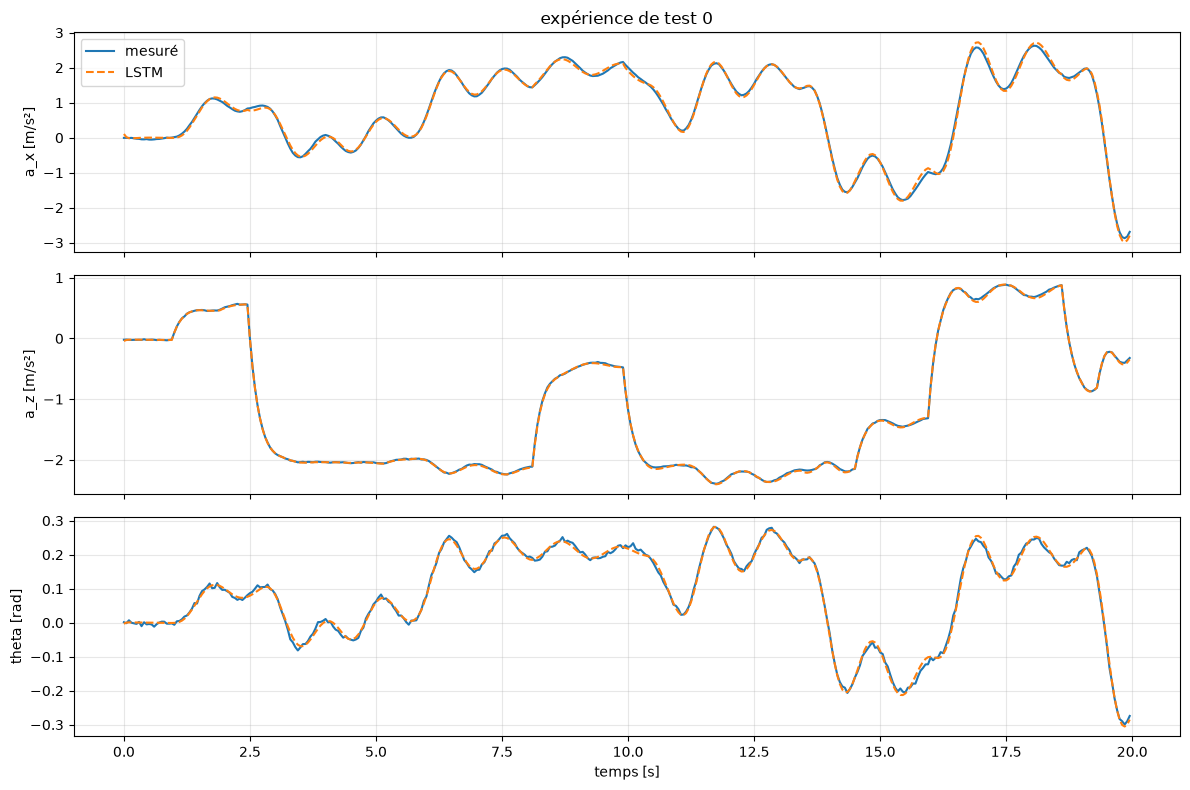

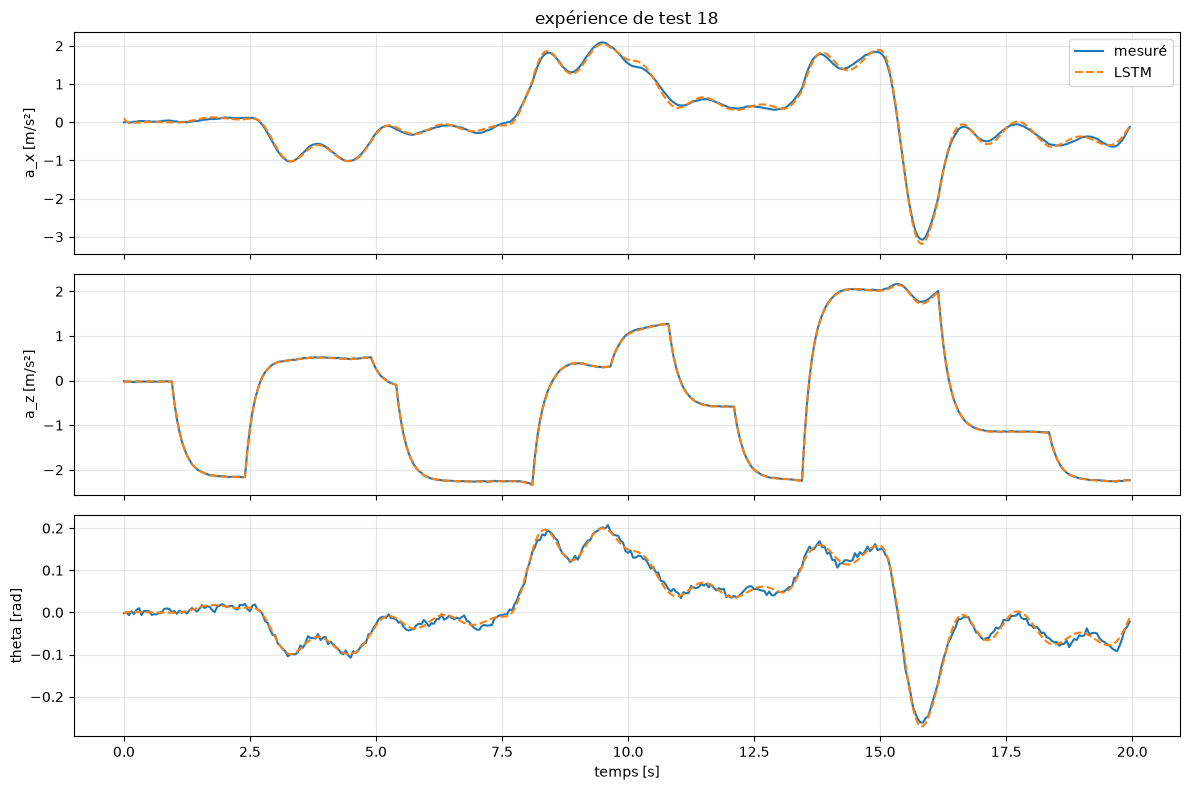

In [22]:
t = np.arange(Y_test.shape[1]) * Ts
for i in [0, pire]:
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for k, ax in enumerate(axes):
        ax.plot(t, Y_test[i, :, k], label="mesuré")
        ax.plot(t, pred_all[i, :, k], "--", label="LSTM")
        ax.set_ylabel(out_names[k]); ax.grid(True, alpha=0.3)
    axes[0].legend(); axes[0].set_title(f"expérience de test {i}"); axes[-1].set_xlabel("temps [s]")
    plt.tight_layout(); plt.show()

Comme en 1D : l'environnement intègre les accélérations, donc on regarde l'erreur de position qu'elles produisent sur 10 s (la durée d'un épisode).

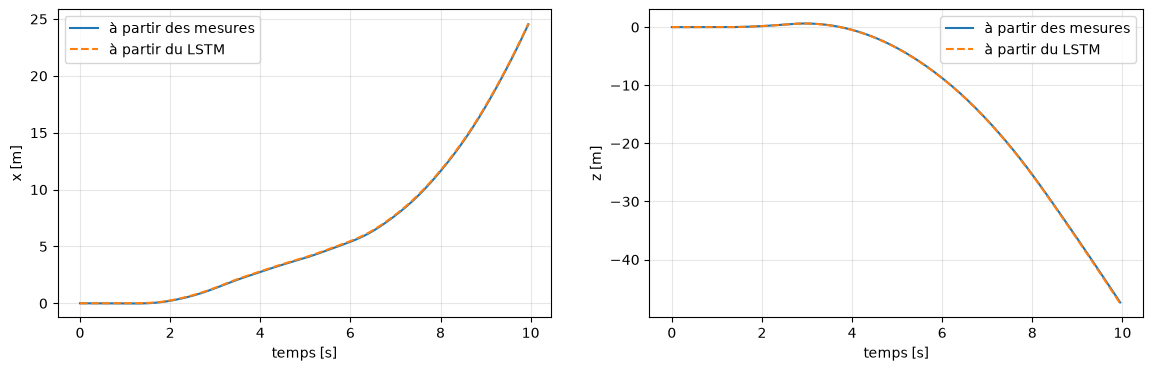

In [23]:
def integrer(a):
    v = np.cumsum(a) * Ts
    return np.cumsum(v) * Ts

i, duree = 0, 200
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, k, n in zip(axes, [0, 1], ["x [m]", "z [m]"]):
    ax.plot(t[:duree], integrer(Y_test[i, :duree, k]), label="à partir des mesures")
    ax.plot(t[:duree], integrer(pred_all[i, :duree, k]), "--", label="à partir du LSTM")
    ax.set_ylabel(n); ax.set_xlabel("temps [s]"); ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

Sauvegarde du modèle et des scalers

In [24]:
import os, shutil, json
os.makedirs("../../models", exist_ok=True)
shutil.copy(checkpoint.best_model_path, "../../models/lstm_2d.ckpt")
json.dump({"u_min": scaler_u.data_min_.tolist(), "u_max": scaler_u.data_max_.tolist(),
           "y_min": scaler_y.data_min_.tolist(), "y_max": scaler_y.data_max_.tolist(),
           "inputs": ["U_common", "theta_cmd"], "outputs": ["ax", "az", "theta"], "Ts": Ts},
          open("../../models/lstm_2d_scaler.json", "w"), indent=2)